# MECHA, 1: water across a root

**What you will learn:** solve how water crosses a root, from the soil to the xylem, with MECHA's default parameters.
Then read its results (the root's conductivity, the water potential in each tissue, the paths the water takes) and
draw them.

**You need:** basic Python (running a cell, calling a function). No knowledge of plant hydraulics or of metafspm is
assumed. **Run time:** about 10 seconds.

This is the first of six user tutorials:

| | notebook | what you do |
|---|---|---|
| 1 | `01_first_run.ipynb` | solve the water flow across a root section, read and draw its results |
| 2 | `02_change_a_parameter.ipynb` | find the parameters, change one, the barriers, another anatomy |
| 3 | `03_combine_parameters.ipynb` | explore two parameters together |
| 4 | `04_sensitivity_analysis.ipynb` | find which parameters matter most for kr |
| 5 | `05_experimental_data.ipynb` | use measured anatomies, compare with observed kr, fit a parameter |
| 6 | `06_along_a_root.ipynb` | a whole root axis, with sections of different maturity |

Developers who want to understand how the model is written and ported will find a second series in
`../developer/`, best read after this one.

## What MECHA represents

A root takes up water from the soil and passes it to its **xylem vessels**, the pipes that carry it up to the
leaves. On its way across the root, from the outside in, the water crosses several **tissues** (layers of cells):

- the **epidermis**, the skin, and below it the **exodermis**;
- the **cortex**, several layers of large cells;
- the **endodermis**, a single layer of cells around the centre;
- the **pericycle** and the **stele** (the central cylinder), which holds the xylem vessels.

Water can take three paths:

- **apoplastic**: along the **cell walls**, outside the cells, like water soaking through a sponge;
- **transmembrane**: across the cells' **membranes**, helped by **aquaporins**, protein channels for water;
- **symplastic**: from cell to cell through **plasmodesmata**, tiny channels joining neighbouring cells.

The walls of the endodermis carry a **Casparian strip**, a waterproof band that blocks the apoplastic path. There,
water must cross a membrane. Older roots add **suberin**, a waxy layer that also blocks the membranes.

What drives the water is the **water potential**, a measure of the water's energy, in hectopascals (hPa). Water
flows from a high potential to a low one. A wet soil is near 0 hPa; the xylem, pulled by the leaves' transpiration,
is at a negative potential, here −5000 hPa (−0.5 MPa).

**MECHA** (Couvreur et al., 2018) computes this flow cell by cell. It represents the root's **cross section**, a thin
slice through it, as a network: each cell, each wall and each wall junction is a node, and each possible passage
between them is an edge with its own conductance. The section's anatomy (its cells and their shapes) is generated
by **GRANAP**, another package. From the flow, MECHA gives the root's **radial conductivity kr**: the water taken up
per unit of root surface and per unit of potential difference between the soil and the xylem.

*Reference:* Couvreur V., Faget M., Lobet G., Javaux M., Chaumont F., Draye X. (2018). Going with the flow:
multiscale insights into the composite nature of water transport in roots. *Plant Physiology* 178, 1689–1703.

*A word on metafspm:* this package is written with metafspm, a framework in which plant models are built as
**components** that can be combined (an anatomy model, a hydraulic model, a soil model...). You do not need to know
it to use MECHA; the developer tutorials and metafspm's own tutorial explain it.

## 1. Solve a root section

`simulate` generates a root cross section with GRANAP (by default a monocot root, like maize or wheat) and solves
the water flow across it with MECHA's **default parameters**. The soil is at 0 hPa, the xylem at −5000 hPa, and the
endodermis has a Casparian strip.

In [1]:
import matplotlib.pyplot as plt

from openalea.mecha.simulation import simulate

result = simulate()

## 2. The summary

`result.summary` gathers the main results:

| entry | meaning | unit |
|---|---|---|
| `kr` | radial conductivity, in MECHA's units | cm hPa⁻¹ d⁻¹ |
| `kr_SI` | the same in the units most publications use | m s⁻¹ MPa⁻¹ |
| `uptake` | water entering the section per day | cm³ d⁻¹ |
| `perimeter` | the section's perimeter | cm |
| `cells` | number of cells in the section | – |
| `cortex_wall_share` | share of the water crossing the cortex along the walls | fraction |
| `cortex_membrane_share` | ... across the membranes | fraction |
| `cortex_plasmodesmata_share` | ... through the plasmodesmata | fraction |

MECHA works in centimetres, hectopascals and days.

In [2]:
result.summary

kr                            1.101081e-04
kr_SI                         1.274400e-07
uptake                        2.771661e-03
perimeter                     2.517217e-01
cells                         1.380000e+03
cortex_wall_share             9.514502e-01
cortex_membrane_share         3.533618e-02
cortex_plasmodesmata_share    1.321362e-02
dtype: float64

**Reading it.**

- kr is about 1.1 × 10⁻⁴ cm hPa⁻¹ d⁻¹, that is 1.3 × 10⁻⁷ m s⁻¹ MPa⁻¹. That is the order of magnitude measured on
  young maize roots.
- In the cortex, about 95 % of the water travels along the cell walls: the apoplastic path is by far the easiest
  there.
- The section is 0.2 mm high (MECHA's standard slice), so the uptake is small, 2.8 × 10⁻³ cm³ per day.

## 3. Draw the section

`result.draw("tissues")` shows the cells coloured by tissue; `result.draw("potential")` colours them by their water
potential.

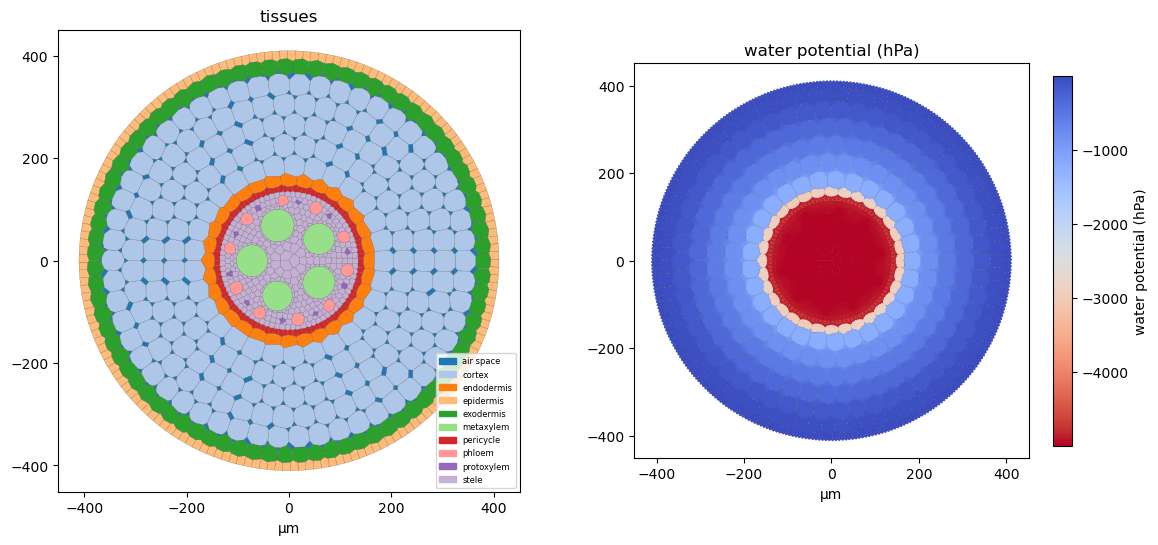

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
result.draw("tissues", ax=axes[0])
result.draw("potential", ax=axes[1])
axes[1].set_title("water potential (hPa)");

The outer tissues are close to the soil's potential (blue), the stele close to the xylem's (red). The sharp change
is at the endodermis: it is the main resistance to the water's path.

## 4. Tissue by tissue

`result.tissues()` gives, for each tissue from the outside in, its number of cells, their total area (µm²) and their
mean water potential (hPa):

In [4]:
tissues = result.tissues()
tissues.round(1)

,cells,area,potential
tissue,,,
epidermis,168,43191.2,-13.5
exodermis,79,67680.1,-54.1
air space,367,17840.2,-394.4
cortex,206,311561.3,-529.4
endodermis,32,20737.6,-2901.8
pericycle,97,10149.6,-4682.2
protoxylem,10,844.9,-5000.0
phloem,10,4337.8,-4946.4
stele,406,36925.1,-4967.2


The potential falls by only about 500 hPa from the soil to the cortex, then by about 4000 hPa from the cortex to
the pericycle, across the endodermis. The walls carry the water easily up to the endodermis; there the Casparian strip forces it through the
membranes.

(The *air spaces* are gaps between cortex cells, filled with air: water does not cross them.)

## 5. The paths of the water

`result.draw("pathways")` shows, from the centre (left) to the surface (right), the share of the water carried by
each path. `result.pathways()` gives the same as a table, one row per layer of cells (`radius` in µm).

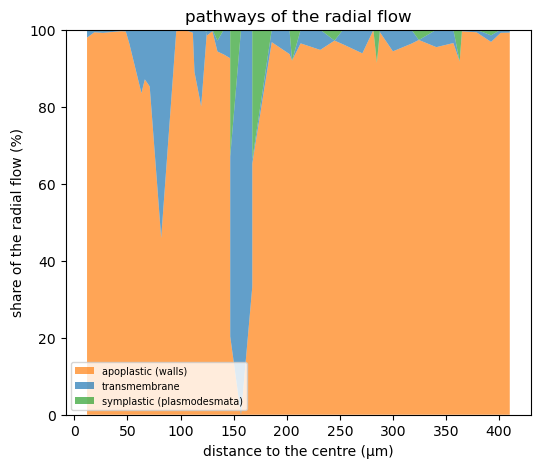

In [5]:
result.draw("pathways");

In the cortex (right part), the walls carry almost everything. At the endodermis the wall share collapses, and the
water passes through membranes and plasmodesmata. Inside the stele, the walls take over again.

## Try it yourself

1. Look at `result.pathways()`. At which radius is the membrane share the largest? Which tissue is there (compare
   with the radii in the drawing)?
2. Solve a section with the soil at −1000 hPa (`simulate(soil_psi=-1000.)`). What happens to the uptake? And to kr?
   Why?
3. Convert kr by hand from cm hPa⁻¹ d⁻¹ to m s⁻¹ MPa⁻¹ and check `kr_SI`.

**Next:** `02_change_a_parameter.ipynb`, to change the root's properties.

## Behind `simulate`: how the model is meant to be used

`simulate` is a convenience for these tutorials, not the model itself. MECHA itself is the component
`MechaHydraulics` (in `openalea.mecha.component`). In metafspm a component is not run on its own. Its intended use
has three layers:

1. **The components.** `MechaHydraulics` holds MECHA's rules: the conductances of walls, membranes and plasmodesmata,
   and the flow they give. It works on the plant's data (each cell, wall and edge of each section) but does not
   create a plant or an anatomy by itself. GRANAP's component, `GranapAnatomy`, writes the sections' cells and walls
   into that data.
2. **A plant model** (a metafspm `CompositeModel`) gathers the components of a plant: here GRANAP's anatomy and
   MECHA's hydraulics, but there could also be a root architecture, a development model setting the barriers' stage,
   or a solute model. The plant model **couples** them, connecting what one computes to what another needs. For
   example, the walls' lengths GRANAP computes are inputs of MECHA.
3. **A scene** (a metafspm `Scene`) plants one or several plants of that model, possibly with an environment (a
   soil model giving each root its soil's water potential). It advances them all, step by step.

`simulate` builds the simplest case: a plant model with GRANAP's anatomy and MECHA's hydraulics, one root segment
in a scene, its barriers set before the solve. Then it summarises the results as tables. To use MECHA with other
models, on whole roots or several plants, you write the plant model and the scene yourself.

- metafspm's beginner page, ["metafspm in five minutes"](https://github.com/openalea/metafspm/blob/data_structure_api/docs/five_minutes.md), explains components, plant
  models and scenes in plain words.
- The developer tutorial `../developer/01_granap_mecha.ipynb` shows how to write them: the plant model of GRANAP and
  MECHA, its scenarios, an input from another model. Its overview, `../developer/00_overview.ipynb`, describes the
  package.